
# Train Soccer Player Detector




## Configure API keys

- Open your [`Roboflow Settings`](https://app.roboflow.com/settings/api) page. Click `Copy`. This will place your private key in the clipboard.
- In Colab, go to the left pane and click on `Secrets` (🔑). Store Roboflow API Key under the name `ROBOFLOW_API_KEY`.

## Before you start

Let's make sure that we have access to GPU. We can use `nvidia-smi` command to do that. In case of any problems navigate to `Edit` -> `Notebook settings` -> `Hardware accelerator`, set it to `GPU`, and then click `Save`.

In [1]:
!nvidia-smi

Fri Oct 30 00:37:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
HOME = os.getcwd()
print(HOME)

/content


## Install dependencies

In [3]:
!pip install -q ultralytics roboflow
!pip install -q modal

# Connect to Modal Labs

In [10]:
import os
import getpass
import subprocess

os.environ["MODAL_TOKEN_ID"] = getpass.getpass(
    "Dán Token ID (ak-...): "
).strip()

os.environ["MODAL_TOKEN_SECRET"] = getpass.getpass(
    "Dán Token Secret (as-...): "
).strip()

result = subprocess.run(
    ["modal", "token", "info"],
    timeout=30,
)

print(
    "Xác thực thành công."
    if result.returncode == 0
    else "Xác thực chưa thành công."
)

Dán Token ID (ak-...): ··········
Dán Token Secret (as-...): ··········
Xác thực thành công.


# Select GPU

In [11]:
import sys
import modal

python_version = f"{sys.version_info.major}.{sys.version_info.minor}"

app = modal.App("verify-modal-gpu")
image = modal.Image.debian_slim(python_version=python_version)

@app.function(image=image, gpu="L40S", timeout=120)
def check_modal_gpu():
    import subprocess

    return subprocess.check_output(
        [
            "nvidia-smi",
            "--query-gpu=name,memory.total",
            "--format=csv,noheader",
        ],
        text=True,
    ).strip()

with modal.enable_output():
    with app.run():
        print("GPU thực tế bên Modal:", check_modal_gpu.remote())

✓ Initialized. View run at 
https://modal.com/apps/luluchi19/main/ap-xWgRA16HmpyRLwPivNcAdI
✓ Created objects.
└── ✓ Created Function check_modal_gpu.
GPU thực tế bên Modal: NVIDIA L40S, 46068 MiB
Stopping app - local entrypoint completed.
✓ App completed. View run at 
https://modal.com/apps/luluchi19/main/ap-xWgRA16HmpyRLwPivNcAdI


## Imports

In [12]:
from roboflow import Roboflow
from google.colab import userdata
from IPython.display import Image

## Pull dataset

In [13]:
!mkdir {HOME}/datasets
%cd {HOME}/datasets

ROBOFLOW_API_KEY = userdata.get('ROBOFLOW_API_KEY')
rf = Roboflow(api_key=ROBOFLOW_API_KEY)

project = rf.workspace("roboflow-jvuqo").project("football-players-detection-3zvbc")
version = project.version(12)
dataset = version.download("yolov8")


/content/datasets
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to football-players-detection-12 in yolov8:: 100%|██████████| 756/756 [00:00<00:00, 3965.12it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [14]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**NOTE:** Update `data.yaml` structure to align with the latest requirements of the `ultralytics` package.



In [15]:
!sed -i 's|\(train: \).*|\1../train/images|' {dataset.location}/data.yaml
!sed -i 's|\(val: \).*|\1../valid/images|' {dataset.location}/data.yaml

## Custom training

In [16]:
import sys
import modal
from google.colab import userdata

app = modal.App("football-yolov8-training")

volume = modal.Volume.from_name(
    "football-yolo-v12",
    create_if_missing=True,
    version=2,
)

roboflow_secret = modal.Secret.from_dict({
    "ROBOFLOW_API_KEY": userdata.get("ROBOFLOW_API_KEY").strip()
})

python_version = f"{sys.version_info.major}.{sys.version_info.minor}"

image = (
    modal.Image.debian_slim(python_version=python_version)
    .apt_install("libgl1", "libglib2.0-0")
    .pip_install("ultralytics", "roboflow", "pyyaml")
)

In [17]:
@app.function(
    image=image,
    secrets=[roboflow_secret],
    volumes={"/storage": volume},
    timeout=1800,
)
def prepare_dataset():
    import os
    from pathlib import Path
    import yaml
    from roboflow import Roboflow

    root = Path("/storage/dataset")
    ready = root / ".ready"

    if ready.exists():
        print("Dataset đã có, không tải lại.")
        return

    rf = Roboflow(api_key=os.environ["ROBOFLOW_API_KEY"])
    project = rf.workspace("roboflow-jvuqo").project(
        "football-players-detection-3zvbc"
    )
    project.version(12).download("yolov8", location=str(root))

    yaml_path = root / "data.yaml"
    config = yaml.safe_load(yaml_path.read_text())

    # Dùng đường dẫn tuyệt đối ở phía Modal.
    config["path"] = str(root)
    config["train"] = str(root / "train/images")

    val_images = next(
        (
            root / split / "images"
            for split in ("valid", "val")
            if (root / split / "images").is_dir()
        ),
        None,
    )

    assert (root / "train/images").is_dir(), "Thiếu train/images"
    assert val_images is not None, "Thiếu valid/images hoặc val/images"

    config["val"] = str(val_images)

    if (root / "test/images").is_dir():
        config["test"] = str(root / "test/images")
    else:
        config.pop("test", None)

    yaml_path.write_text(yaml.safe_dump(config, sort_keys=False))
    ready.touch()
    volume.commit()

    print("Dataset version 12 đã sẵn sàng.")
    print(yaml_path.read_text())


@app.function(
    image=image,
    gpu="L40S",
    cpu=4,
    memory=16384,
    volumes={"/storage": volume},
    timeout=4 * 60 * 60,
)
def train_football(epochs: int = 50, batch_size: int = 6):
    from datetime import datetime
    from pathlib import Path
    import torch
    from ultralytics import YOLO

    volume.reload()
    data_yaml = "/storage/dataset/data.yaml"
    assert Path("/storage/dataset/.ready").exists(), "Chạy prepare_dataset trước"

    print("GPU train:", torch.cuda.get_device_name(0))

    run_name = datetime.now().strftime("football-%Y%m%d-%H%M%S")
    model = YOLO("yolov8x.pt")

    def save_to_volume(trainer):
        volume.commit()

    model.add_callback("on_model_save", save_to_volume)

    try:
        model.train(
            data=data_yaml,
            batch=batch_size,
            epochs=epochs,
            imgsz=1280,
            device=0,
            amp=True,
            workers=4,
            cache=False,
            plots=True,
            save=True,
            project="/storage/runs",
            name=run_name,
        )
        return str(model.trainer.save_dir)
    finally:
        volume.commit()

In [19]:
with modal.enable_output():
    with app.run():
        save_dir = train_football.remote(
            epochs=50,
            batch_size=6,
        )

print("Kết quả trên Modal:", save_dir)

✓ Initialized. View run at 
https://modal.com/apps/luluchi19/main/ap-NaAauMIe4d59VuhEpQiTRC
✓ Created objects.
├── ✓ Created Function prepare_dataset.
└── ✓ Created Function train_football.
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU train: NVIDIA L40S

Ultralytics 8.4.193 🚀 Python-3.13.3 torch-2.15.0+cu132 CUDA:0 (NVIDIA L40S, 48540MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=6, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/storage/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1

[modal-client] 2026-10-30T01:11:35+0000 Timed out waiting for final app logs.


✓ App completed. View run at 
https://modal.com/apps/luluchi19/main/ap-NaAauMIe4d59VuhEpQiTRC
Kết quả trên Modal: /__modal/volumes/vo-bMfUtjfJ7XC9NWU2OKcFZT/runs/football-20261030-005646


In [23]:
from pathlib import Path
import tempfile

RUN_NAME = "football-20261030-005646"
VOLUME_NAME = "football-yolo-v12"

# Tạo thư mục mới, bảo đảm không trùng đường dẫn cũ.
LOCAL_RUN = Path(tempfile.mkdtemp(
    prefix=f"{RUN_NAME}-",
    dir="/content",
))

print("Thư mục tải kết quả:", LOCAL_RUN)

files_to_download = [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "results.png",
    "results.csv",
    "args.yaml",
    "val_batch0_pred.jpg",
    "val_batch0_labels.jpg",
    "weights/best.pt",
    "weights/last.pt",
]

for filename in files_to_download:
    destination = LOCAL_RUN / filename
    destination.parent.mkdir(parents=True, exist_ok=True)

    result = subprocess.run(
        [
            "modal", "volume", "get",
            VOLUME_NAME,
            f"/runs/{RUN_NAME}/{filename}",
            str(destination),
            "--force",
        ],
        capture_output=True,
        text=True,
    )

    if result.returncode == 0:
        print("Đã tải:", filename)
    else:
        print("Không tải được:", filename)
        print(result.stderr.strip())

Thư mục tải kết quả: /content/football-20261030-005646-0vbnc27b
Đã tải: confusion_matrix.png
Đã tải: confusion_matrix_normalized.png
Đã tải: results.png
Đã tải: results.csv
Đã tải: args.yaml
Đã tải: val_batch0_pred.jpg
Đã tải: val_batch0_labels.jpg
Đã tải: weights/best.pt
Đã tải: weights/last.pt


In [ ]:
!ls {HOME}/runs/detect/train/

args.yaml					    R_curve.png		 val_batch0_labels.jpg
confusion_matrix_normalized.png			    results.csv		 val_batch0_pred.jpg
confusion_matrix.png				    results.png		 val_batch1_labels.jpg
events.out.tfevents.1721676020.920454bd5944.1065.0  train_batch0.jpg	 val_batch1_pred.jpg
F1_curve.png					    train_batch1680.jpg  val_batch2_labels.jpg
labels_correlogram.jpg				    train_batch1681.jpg  val_batch2_pred.jpg
labels.jpg					    train_batch1682.jpg  weights
P_curve.png					    train_batch1.jpg
PR_curve.png					    train_batch2.jpg


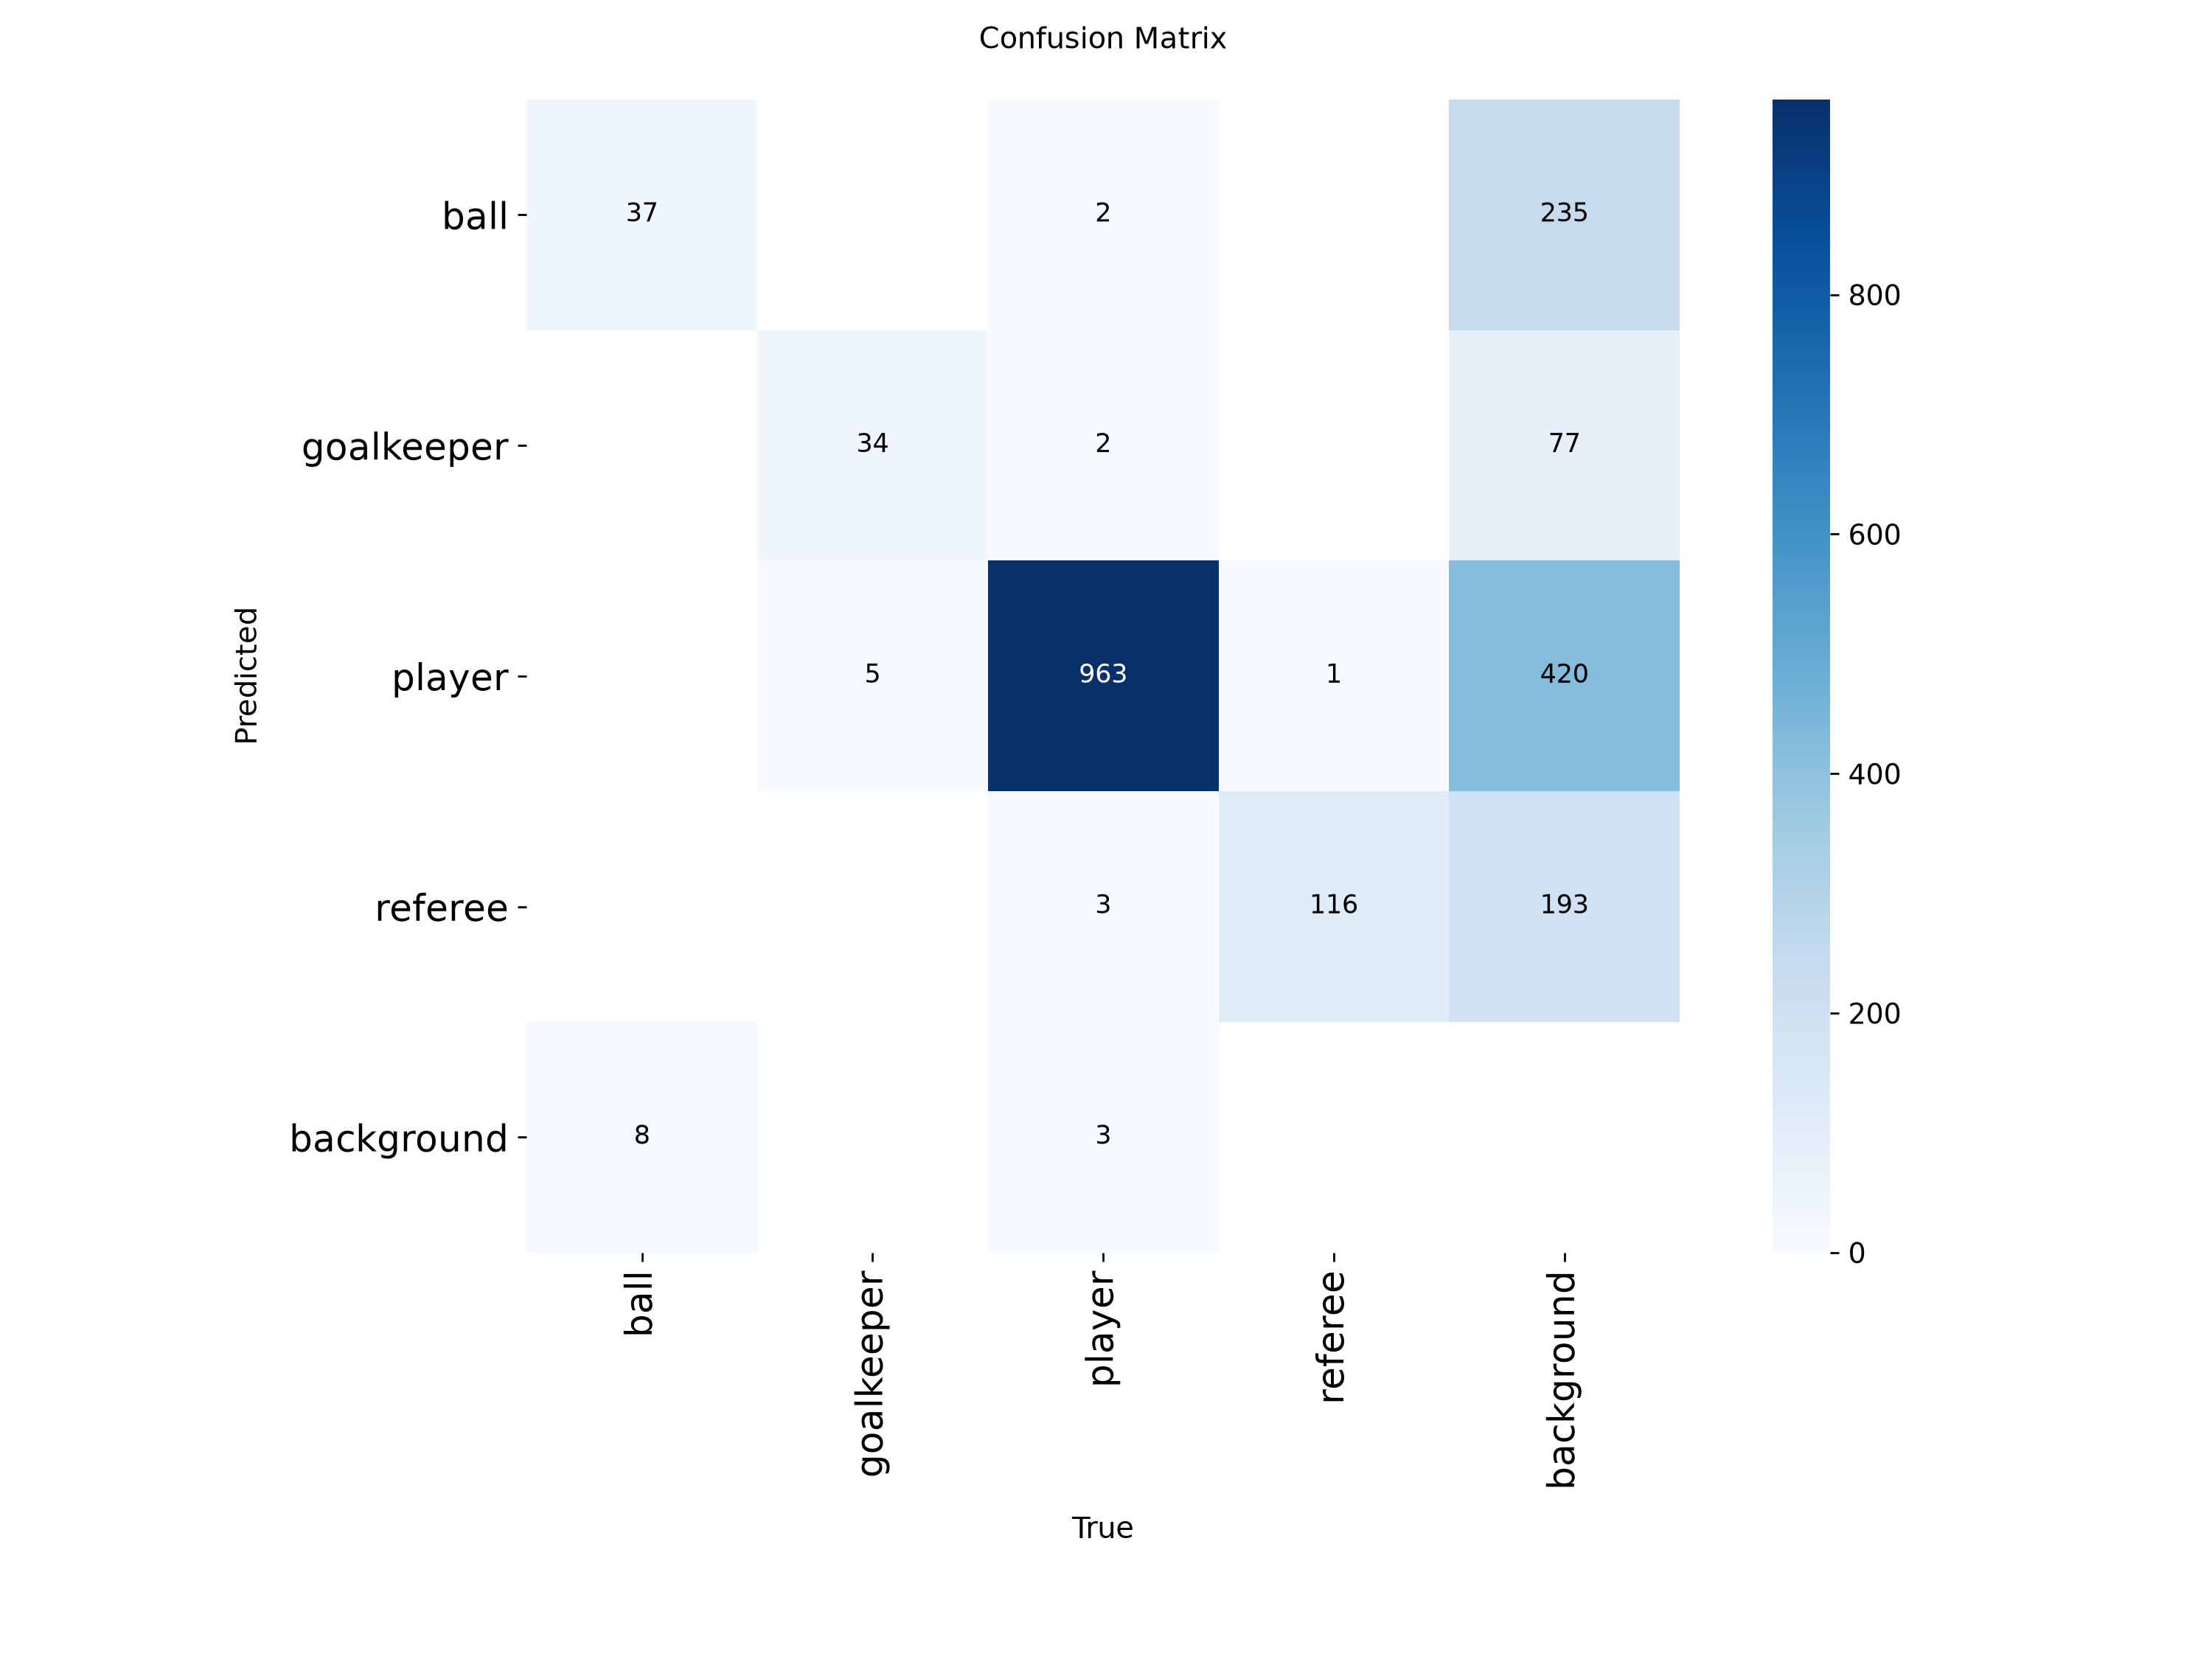

In [24]:
from IPython.display import Image, display

display(Image(
    filename=str(LOCAL_RUN / "confusion_matrix.png"),
    width=800,
))

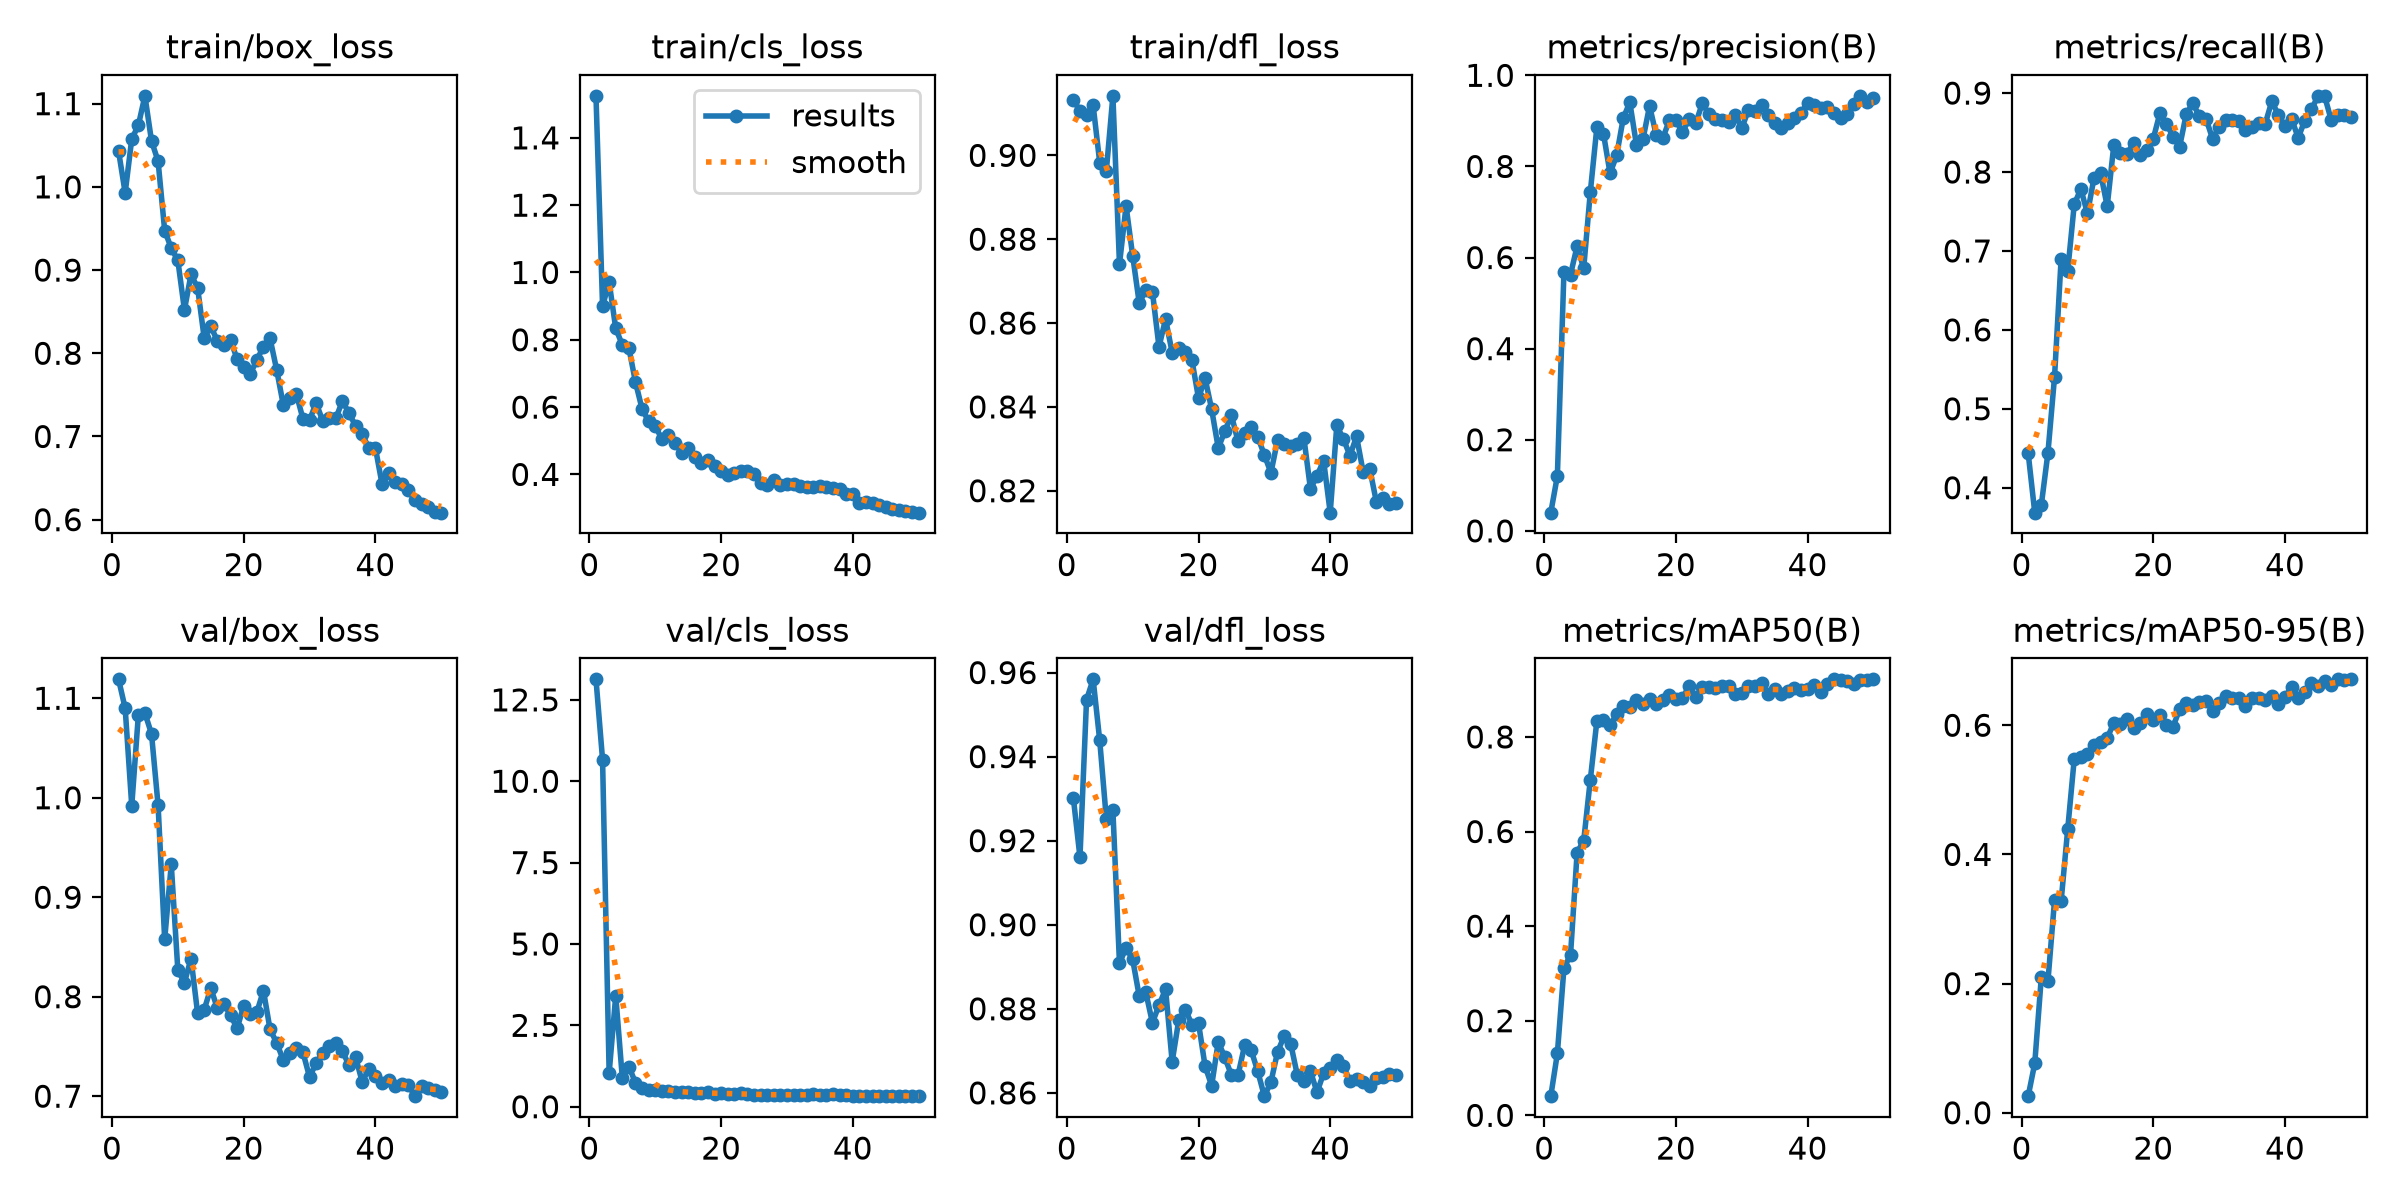

In [25]:
display(Image(
    filename=str(LOCAL_RUN / "results.png"),
    width=1000,
))

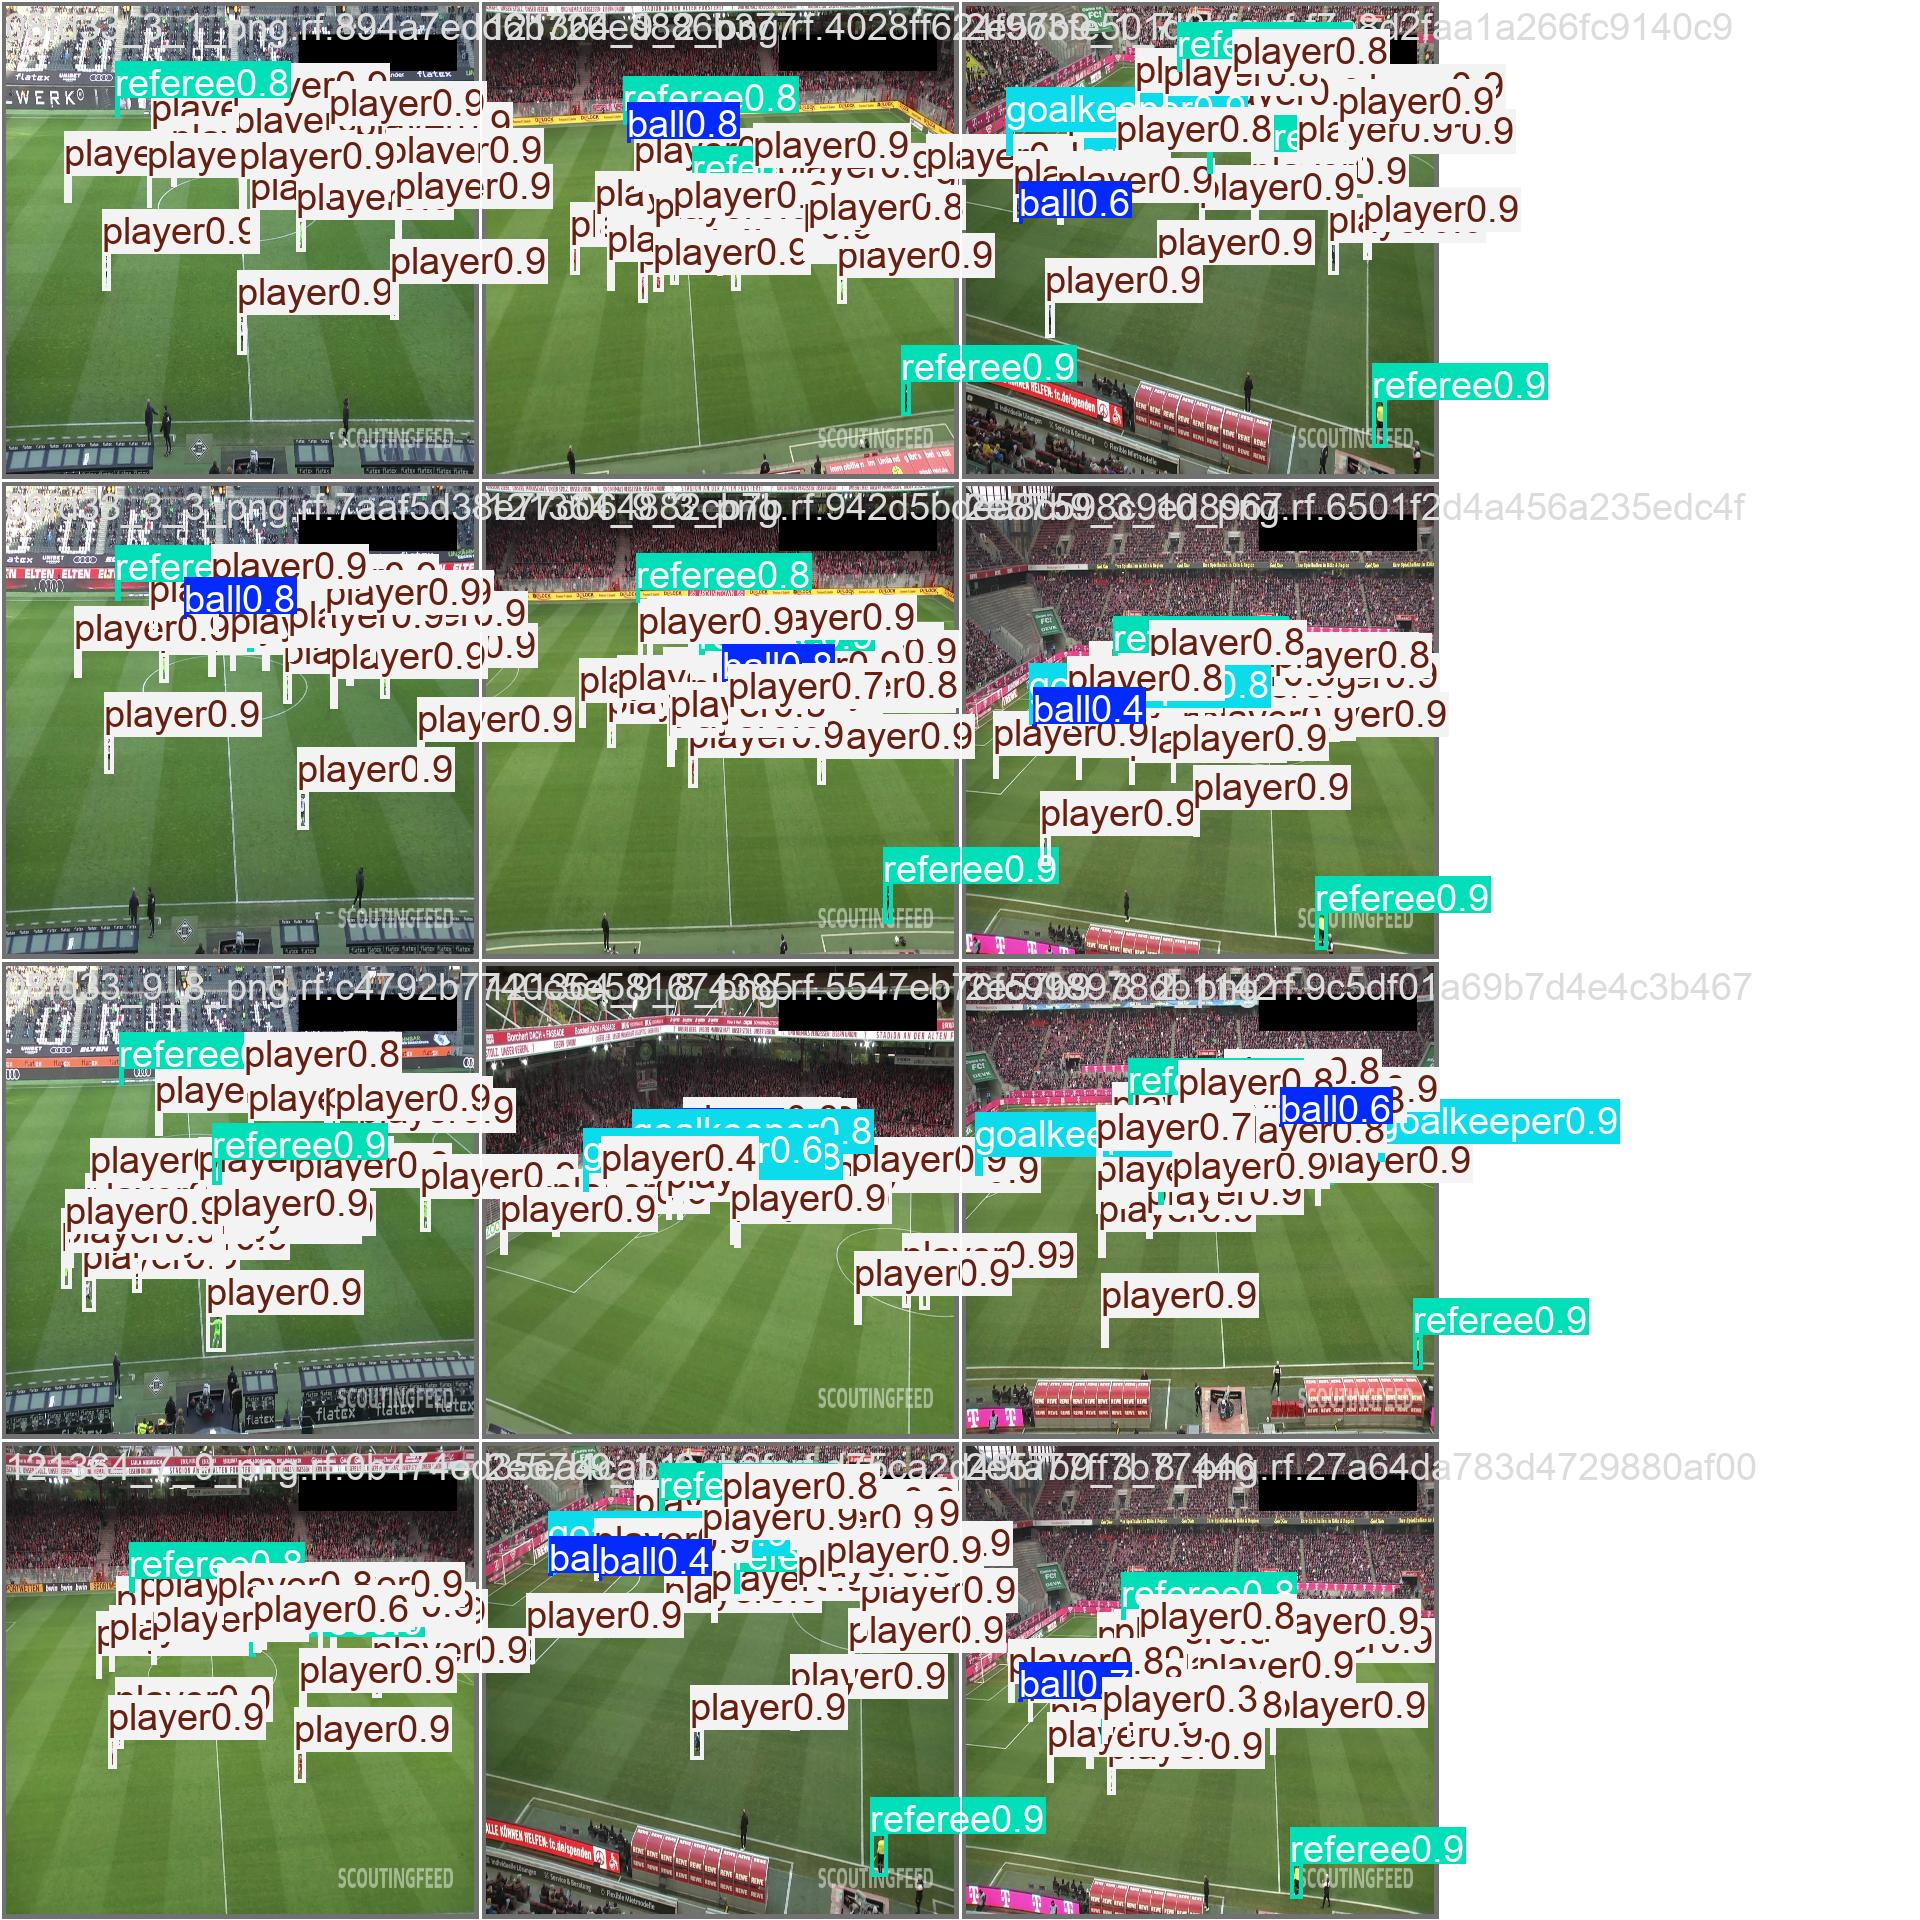

In [26]:
display(Image(
    filename=str(LOCAL_RUN / "val_batch0_pred.jpg"),
    width=1000,
))

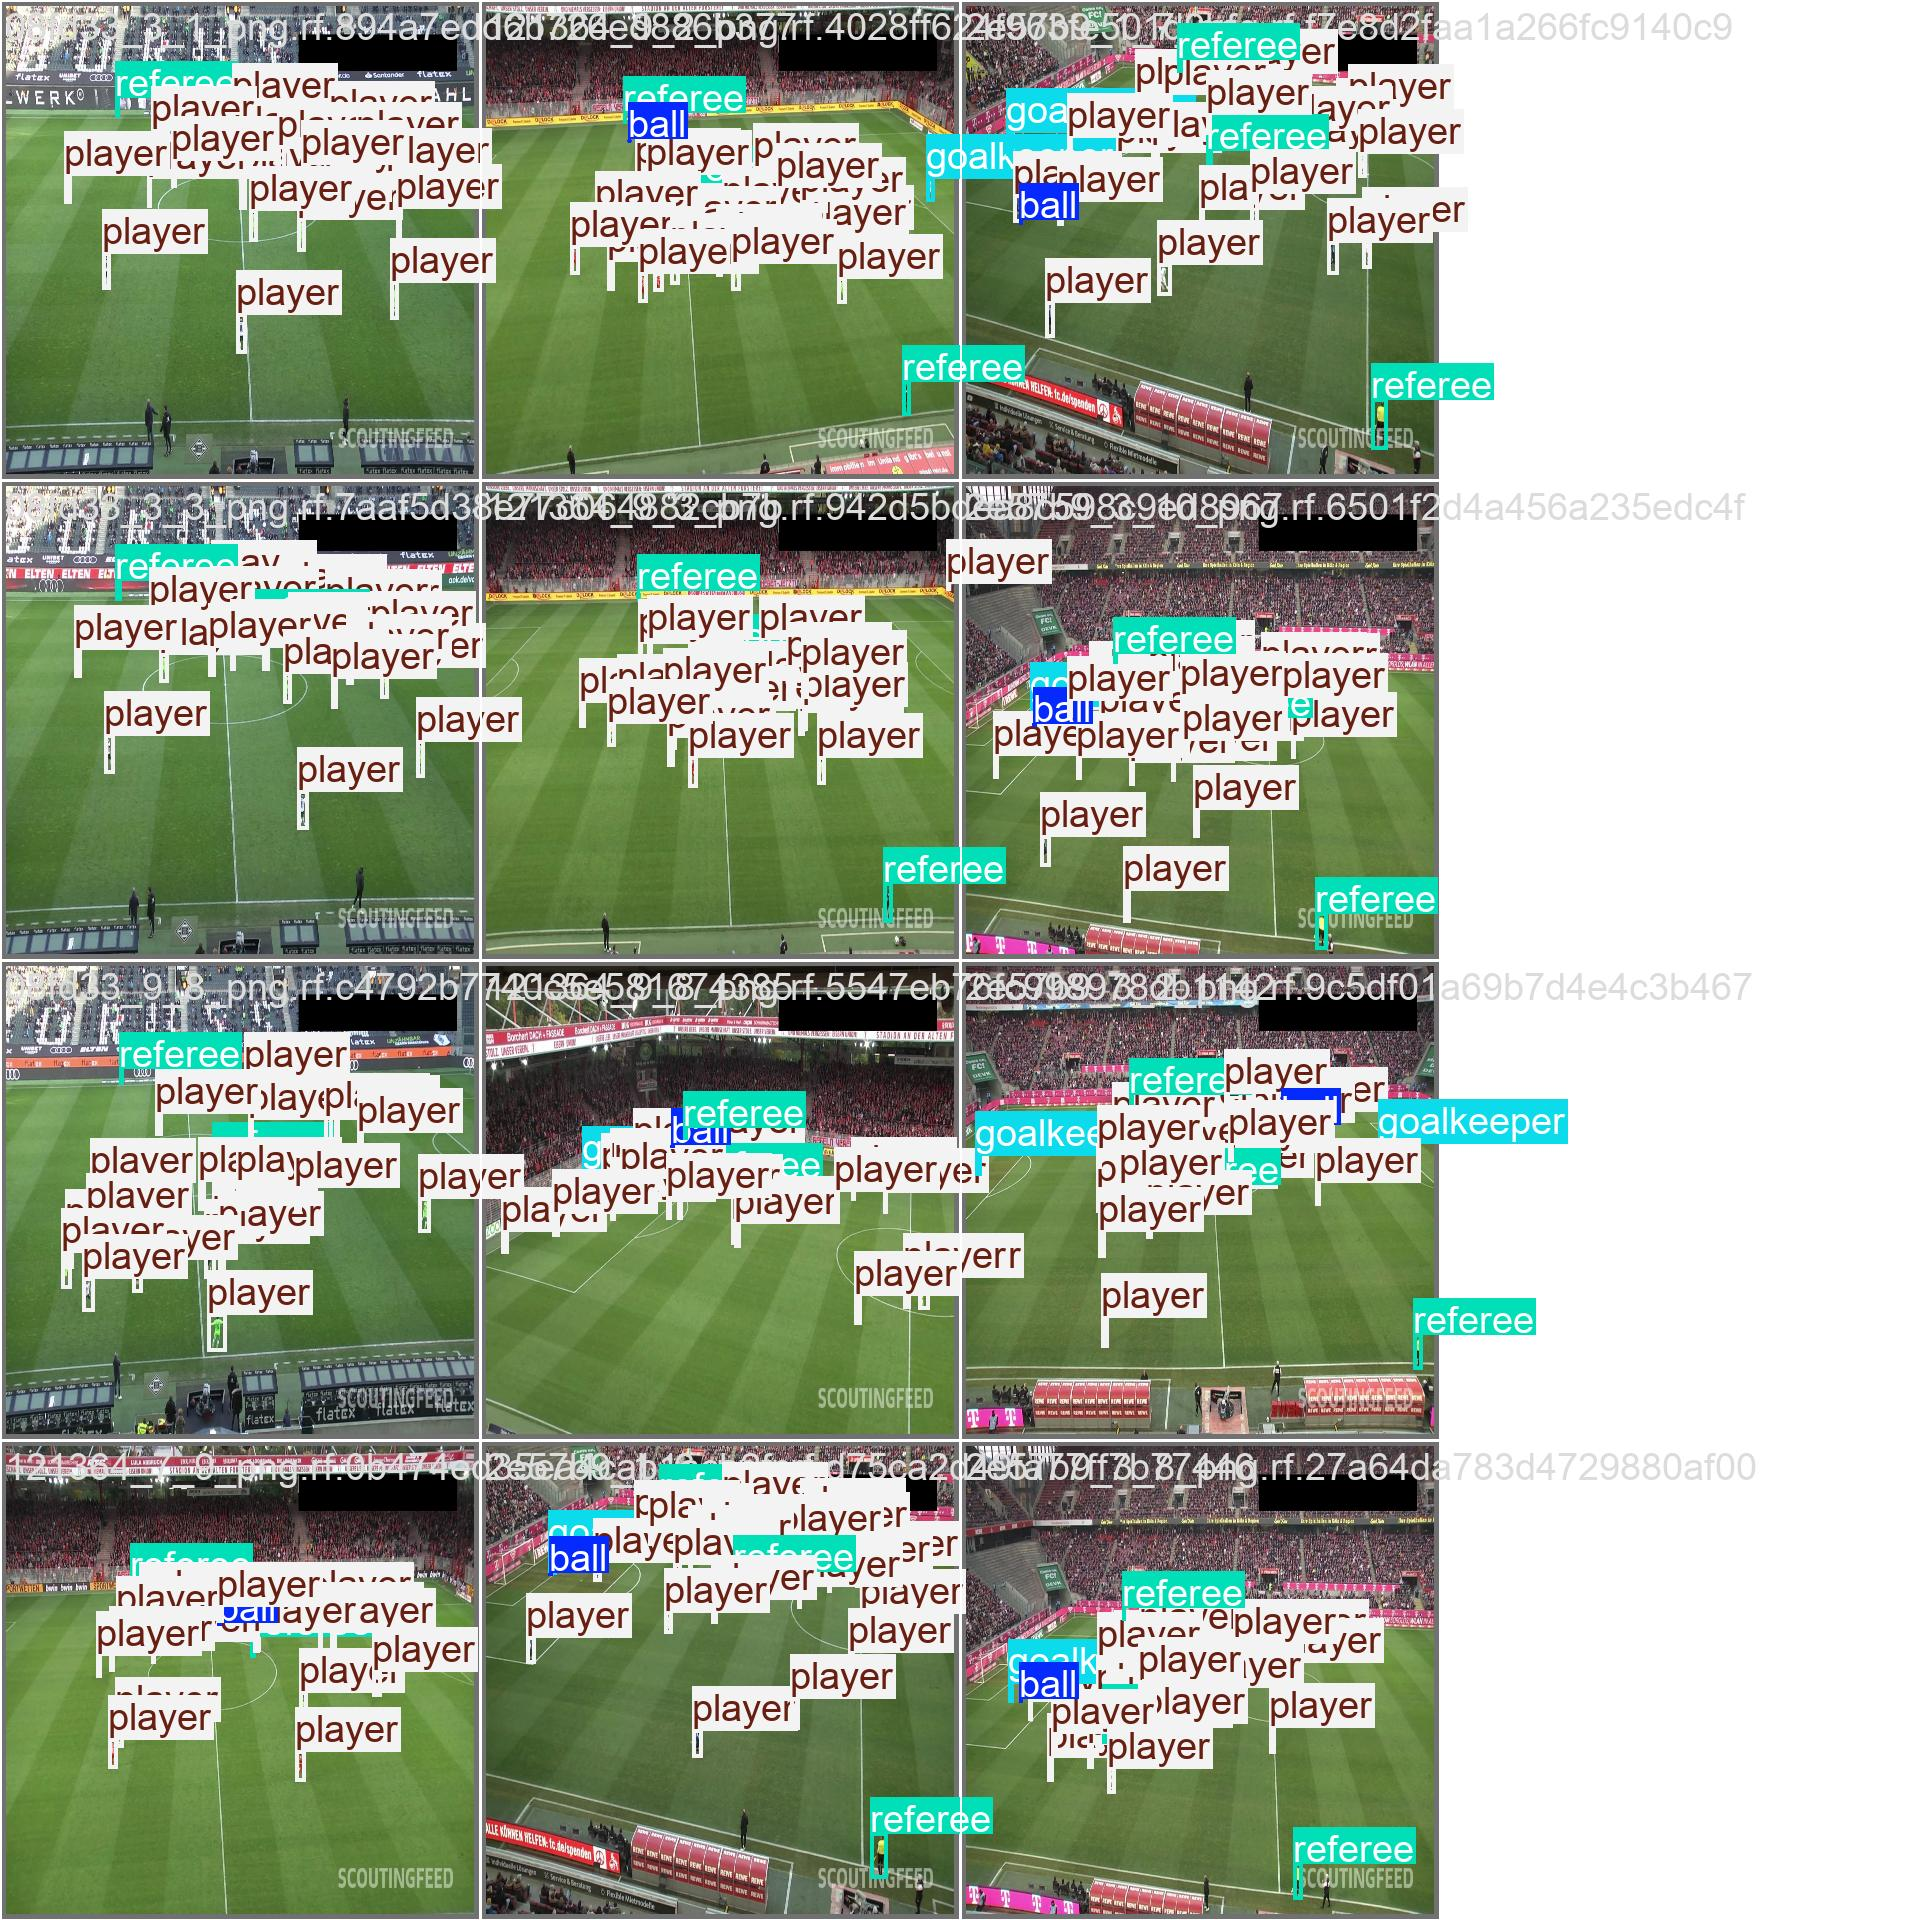

In [27]:
display(Image(
    filename=str(LOCAL_RUN / "val_batch0_labels.jpg"),
    width=1000,
))

## Validate custom model

In [28]:
@app.function(
    image=image,
    gpu="L40S",
    cpu=4,
    memory=16384,
    volumes={"/storage": volume},
    timeout=1800,
)
def validate_football():
    import torch
    from ultralytics import YOLO

    volume.reload()

    run_name = "football-20261030-005646"
    model = YOLO(
        f"/storage/runs/{run_name}/weights/best.pt"
    )

    print("GPU validation:", torch.cuda.get_device_name(0))

    try:
        metrics = model.val(
            data="/storage/dataset/data.yaml",
            split="val",
            imgsz=1280,
            batch=6,
            device=0,
            plots=True,
            project="/storage/evaluations",
            name=run_name,
            exist_ok=True,
        )

        return {
            "precision": float(metrics.box.mp),
            "recall": float(metrics.box.mr),
            "mAP50": float(metrics.box.map50),
            "mAP50-95": float(metrics.box.map),
        }
    finally:
        volume.commit()

In [29]:
with modal.enable_output():
    with app.run():
        metrics = validate_football.remote()

print(metrics)

✓ Initialized. View run at 
https://modal.com/apps/luluchi19/main/ap-zLAwH9lkoq5tbmgeSRQM7p
✓ Created objects.
├── ✓ Created Function prepare_dataset.
├── ✓ Created Function train_football.
└── ✓ Created Function validate_football.
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU validation: NVIDIA L40S
Ultralytics 8.4.193 🚀 Python-3.13.3 torch-2.15.0+cu132 CUDA:0 (NVIDIA L40S, 45486MiB)
Model summary (fused): 112 layers, 68,127,420 parameters, 0 gradients, 257.4 GFLOPs
val: Fast image access ✅ (ping: 0.2±0.1 ms, read: 167.5±117.3 MB/s, size: 182.7 KB)
val: Scanning /__modal/volumes/vo-bMfUtjfJ7XC9NWU2OKcFZT/dataset/valid/labels.cache... 49 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 49/49 10.8Mit/s 0.0s
                 Class     Ima

## Deploy model on Roboflow

In [34]:
from pathlib import Path
from roboflow import Roboflow
from google.colab import userdata

model_dir = Path(LOCAL_RUN)
assert (model_dir / "weights/best.pt").is_file(), "Không tìm thấy best.pt"

rf = Roboflow(
    api_key=userdata.get("ROBOFLOW_API_KEY").strip()
)

target_project = rf.workspace(
    "nguyns-workspace-do3bt"
).project(
    "football-players-detection-3zvbc-kv8oo"
)

target_project.version(1).deploy(
    model_type="yolov8",
    model_path=str(model_dir),
    filename="weights/best.pt",
)

loading Roboflow workspace...
loading Roboflow project...
ultralytics==8.0.196 is recommended for this upload, but ultralytics 8.4.192 is installed. Retry with allow_dependency_mismatch=True to package with the installed version, or `pip install ultralytics==8.0.196`.
Would you like to continue anyway? y/n: y
ultralytics==8.0.196 is recommended for this upload, but ultralytics 8.4.192 is installed.
Inferred model size 'yolov8x' from the checkpoint architecture (model_type was 'yolov8').
View the status of your deployment at: https://app.roboflow.com/nguyns-workspace-do3bt/football-players-detection-3zvbc-kv8oo/1
Share your model with the world at: https://universe.roboflow.com/nguyns-workspace-do3bt/football-players-detection-3zvbc-kv8oo/model/1
